<a href="https://colab.research.google.com/github/tousif47/Geostormcaster/blob/main/02_model_a_t3h.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 — Model A: t+3h storm forecast (G1+, hourly data)

Task: detect geomagnetic storms (Kp >= 5, NOAA G1 threshold) in the next
3-hour block.

- Inputs: 24h windows of 6 physics-informed solar wind features
- Formulation: binary (storm vs. non-storm), sigmoid output, threshold
  swept on validation
- Selection metric: storm F1 on validation; test set used once, at the end
- Comparison: persistence baseline on the identical split

In [1]:
import numpy as np
import json
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report, f1_score

tf.keras.utils.set_random_seed(42)

OUT_DIR = '/content/drive/MyDrive/temp'
CSV     = f'{OUT_DIR}/omni_clean.csv'

D = np.load(f'{OUT_DIR}/windows_a.npz')
XA = {k: D[k] for k in D.files}
print({k: v.shape for k, v in XA.items()})

# storm = G1+ (Kp >= 5), applied on the exact Kp labels stored in the npz
yb_tr = (XA['ytr'] >= 5).astype(np.float32)
yb_va = (XA['yva'] >= 5).astype(np.float32)
CLASS_WEIGHT = {0: 1.0, 1: 8.0}
print(f'train: storm share = {yb_tr.mean():.3f}')

{'Xtr': (240312, 24, 6), 'Xva': (69349, 24, 6), 'Xte': (65960, 24, 6), 'ytr': (240312,), 'yva': (69349,), 'yte': (65960,), 'ttr': (240312,), 'tva': (69349,), 'tte': (65960,)}
train: storm share = 0.043


## Baselines (validation)

Every forecast system is judged against trivial strategies first:

1. **Climatology** — always predict non-storm. On imbalanced data this
   posts a deceptively high accuracy with zero storm detections; it exists
   here to make that trap visible with real numbers.
2. **Persistence** — predict the current block's class ("next = same").
   Kp is strongly autocorrelated over one 3-hour block, so this is a
   genuinely strong baseline at 3h lead. The trained model must beat it.

In [2]:
df = pd.read_csv(CSV, parse_dates=['timestamp']).set_index('timestamp')

def eval_bin(y_true, y_pred, name):
    print(f'--- {name} ---')
    print(confusion_matrix(y_true, y_pred, labels=[0, 1]))
    print(classification_report(y_true, y_pred,
          target_names=['non-storm', 'storm'], digits=3, zero_division=0))
    return f1_score(y_true, y_pred)

f1_climo = eval_bin(yb_va, np.zeros_like(yb_va), 'Climatology (always non-storm)')

cur_kp = df['kp'].reindex(XA['tva']).clip(upper=9).values
f1_persist = eval_bin(yb_va, (cur_kp >= 5).astype(int), 'Persistence')

--- Climatology (always non-storm) ---
[[67852     0]
 [ 1497     0]]
              precision    recall  f1-score   support

   non-storm      0.978     1.000     0.989     67852
       storm      0.000     0.000     0.000      1497

    accuracy                          0.978     69349
   macro avg      0.489     0.500     0.495     69349
weighted avg      0.957     0.978     0.968     69349

--- Persistence ---
[[67075   777]
 [  777   720]]
              precision    recall  f1-score   support

   non-storm      0.989     0.989     0.989     67852
       storm      0.481     0.481     0.481      1497

    accuracy                          0.978     69349
   macro avg      0.735     0.735     0.735     69349
weighted avg      0.978     0.978     0.978     69349



## Candidates

Three architectures, identical training recipe (same optimizer, loss, batch
size, early stopping, class weights) — only the architecture differs, so
the comparison is clean. All use a binary sigmoid head.

1. **MLP on window statistics** — each 24x6 window collapsed to 18 numbers
   (mean/std/min per feature). Tests whether hand-picked summary features
   beat learned ones.
2. **1D-CNN** — learns local temporal motifs in the raw window.
3. **GRU** — recurrent memory of the full 24h sequence.

In [3]:
def window_stats(X):
    return np.concatenate([X.mean(axis=1), X.std(axis=1), X.min(axis=1)], axis=1)

S = {k: (window_stats(v) if k.startswith('X') else v) for k, v in XA.items()}

def make_mlp():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(18,)),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')])

def make_cnn():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(24, 6)),
        tf.keras.layers.Conv1D(32, 3, activation='relu'),
        tf.keras.layers.Conv1D(64, 3, activation='relu'),
        tf.keras.layers.GlobalAveragePooling1D(),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')])

def make_gru():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(24, 6)),
        tf.keras.layers.GRU(16),
        tf.keras.layers.Dense(1, activation='sigmoid')])

def train_bin(make_model, Xtr, Xva, tag, epochs=40, patience=6):
    m = make_model()
    m.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    m.fit(Xtr, yb_tr,
          validation_data=(Xva, yb_va),
          epochs=epochs, batch_size=512, class_weight=CLASS_WEIGHT,
          callbacks=[tf.keras.callbacks.EarlyStopping(
              patience=patience, restore_best_weights=True)],
          verbose=1)
    m.save(f'{OUT_DIR}/model_{tag}.keras')
    return m

## Training

All three candidates train with an identical recipe: same optimizer, loss,
batch size, epoch cap, early stopping, and class weights. Only the
architecture differs, which keeps the comparison that follows clean.

Expected runtime: a few minutes total in Colab. The GRU is the slowest of
the three; a pause near the end of an epoch is the early-stopping check,
not a hang.

In [4]:
m_mlp = train_bin(make_mlp, S['Xtr'], S['Xva'], 'a_mlp')
m_cnn = train_bin(make_cnn, XA['Xtr'], XA['Xva'], 'a_cnn')
m_gru = train_bin(make_gru, XA['Xtr'], XA['Xva'], 'a_gru')

candidates = {'MLP': (m_mlp, S['Xva']),
              '1D-CNN': (m_cnn, XA['Xva']),
              'GRU': (m_gru, XA['Xva'])}

Epoch 1/40
470/470 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8802 - loss: 0.5062 - val_accuracy: 0.9298 - val_loss: 0.1601
Epoch 2/40
470/470 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8937 - loss: 0.4551 - val_accuracy: 0.9373 - val_loss: 0.1505
Epoch 3/40
470/470 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8979 - loss: 0.4456 - val_accuracy: 0.9392 - val_loss: 0.1486
Epoch 4/40
470/470 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8990 - loss: 0.4419 - val_accuracy: 0.9401 - val_loss: 0.1462
Epoch 5/40
470/470 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9004 - loss: 0.4385 - val_accuracy: 0.9405 - val_loss: 0.1457
Epoch 6/40
470/470 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9009 - loss: 0.4358 - val_accuracy: 0.9425 - val_loss: 0.1427
Epoch 7/40
470/470 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9023 - loss: 0.4341 - val_accuracy: 0.9413 - val_loss: 0.1456
Epoch 8/40
470/470 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9024 - loss: 0.4320 - val_accuracy: 0.

## Threshold sweep (validation)

Predict storm when P(storm) > tau, sweeping tau across the validation set.
The chosen tau becomes a fixed constant of the deployed model — like the
normalization constants, it ships with the firmware.

MLP      best tau=0.59  val storm F1=0.332
1D-CNN   best tau=0.71  val storm F1=0.439
GRU      best tau=0.73  val storm F1=0.476


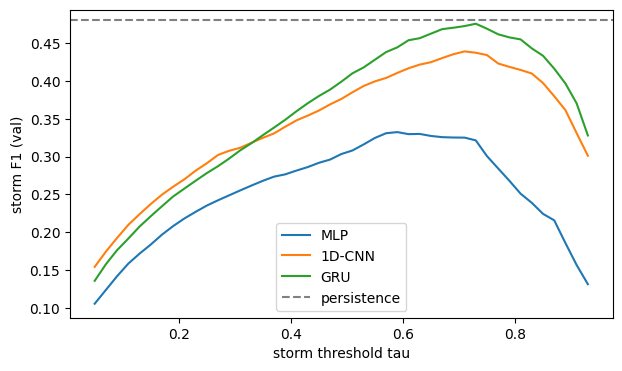

In [5]:
taus = np.arange(0.05, 0.95, 0.02)
swept = {}

plt.figure(figsize=(7, 4))
for name, (m, Xv) in candidates.items():
    p = m.predict(Xv, verbose=0).squeeze()
    f1s = [f1_score(yb_va, (p > t).astype(int)) for t in taus]
    best = int(np.argmax(f1s))
    swept[name] = (float(taus[best]), float(f1s[best]))
    print(f'{name:8s} best tau={taus[best]:.2f}  val storm F1={f1s[best]:.3f}')
    plt.plot(taus, f1s, label=name)

plt.axhline(f1_persist, color='gray', linestyle='--', label='persistence')
plt.xlabel('storm threshold tau'); plt.ylabel('storm F1 (val)')
plt.legend(); plt.show()

## Winner → test set, once

The model with the highest storm F1 on validation (including its tuned
threshold tau) is evaluated below on the test split — data from 2019 onward
that no training or selection decision has seen. This is the single point
where the test set is used, which keeps the final numbers unbiased.

The cell prints the test confusion matrix and precision/recall/F1 for both
classes, then places the model side-by-side with the persistence baseline
on the same split — the comparison that decides whether the model carries
genuine forecasting skill. Everything (winner, tau, all F1 scores, full
classification report) is written to model_a_results.json for the
firmware step and final summary.

In [6]:
winner_name = max(swept, key=lambda n: swept[n][1])
best_tau, best_f1 = swept[winner_name]
print(f'winner: {winner_name} (tau={best_tau:.2f}, val storm F1={best_f1:.3f})')

w_model = candidates[winner_name][0]
if winner_name == 'MLP':
    w_Xte = S['Xte']
else:
    w_Xte = XA['Xte']

p_te = w_model.predict(w_Xte, verbose=0).squeeze()
pred_te = (p_te > best_tau).astype(int)
yb_te = (XA['yte'] >= 5).astype(int)
f1_test = eval_bin(yb_te, pred_te, f'{winner_name} (tau={best_tau:.2f}) on TEST')

cur_kp_te = df['kp'].reindex(XA['tte']).clip(upper=9).values
f1_persist_te = eval_bin(yb_te, (cur_kp_te >= 5).astype(int),
                         'Persistence on TEST')

print('\n===== FINAL COMPARISON (test split) =====')
print(f'{winner_name} (tau={best_tau:.2f})  storm F1 = {f1_test:.3f}')
print(f'Persistence                  storm F1 = {f1_persist_te:.3f}')

summary = {
    'task': 'model_a_t3h_storm_binary_g1',
    'storm_definition': 'Kp >= 5 (G1+)',
    'features': ['bz_gsm', 'speed', 'density', 'newell', 'rect_v', 'pressure'],
    'winner': winner_name,
    'best_tau': best_tau,
    'val_storm_f1': {n: v[1] for n, v in swept.items()},
    'val_storm_f1_baselines': {'climatology': float(f1_climo),
                               'persistence': float(f1_persist)},
    'test_storm_f1': float(f1_test),
    'test_storm_f1_persistence': float(f1_persist_te),
    'test_report': classification_report(yb_te, pred_te,
                      target_names=['non-storm', 'storm'], output_dict=True),
}
with open(f'{OUT_DIR}/model_a_results.json', 'w') as f:
    json.dump(summary, f, indent=2)
print('saved model_a_results.json')

winner: GRU (tau=0.73, val storm F1=0.476)
--- GRU (tau=0.73) on TEST ---
[[63111  1321]
 [  568   960]]
              precision    recall  f1-score   support

   non-storm      0.991     0.979     0.985     64432
       storm      0.421     0.628     0.504      1528

    accuracy                          0.971     65960
   macro avg      0.706     0.804     0.745     65960
weighted avg      0.978     0.971     0.974     65960

--- Persistence on TEST ---
[[63687   745]
 [  745   783]]
              precision    recall  f1-score   support

   non-storm      0.988     0.988     0.988     64432
       storm      0.512     0.512     0.512      1528

    accuracy                          0.977     65960
   macro avg      0.750     0.750     0.750     65960
weighted avg      0.977     0.977     0.977     65960


===== FINAL COMPARISON (test split) =====
GRU (tau=0.73)  storm F1 = 0.504
Persistence                  storm F1 = 0.512
saved model_a_results.json
